In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/datasets')

print("Datasets extracted successfully!")

Saving datsets capstone.zip to datsets capstone (1).zip
Datasets extracted successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries loaded.")

Libraries loaded.


In [ ]:
csv_files = []

for root, dirs, files_ in os.walk('/content/datasets'):
    for file in files_:
        if file.lower().endswith('.csv'):
            csv_files.append(
                os.path.join(root, file)
            )

print("CSV files found:\n")

for i, file in enumerate(csv_files):
    print(i, file)

CSV files found:

0 /content/datasets/datsets capstone/Irrigation Water Requirement Prediction Dataset/irrigation_prediction.csv
1 /content/datasets/datsets capstone/Smart Agriculture Dataset/cropdata_updated.csv


In [ ]:
dataset1_path = [
    f for f in csv_files
    if 'irrigation_prediction' in f.lower()
][0]

dataset2_path = [
    f for f in csv_files
    if 'cropdata_updated' in f.lower()
][0]

df1 = pd.read_csv(dataset1_path)
df2 = pd.read_csv(dataset2_path)

print("Dataset 1 shape:", df1.shape)
print("Dataset 2 shape:", df2.shape)

Dataset 1 shape: (10000, 20)
Dataset 2 shape: (16411, 7)


In [ ]:
data1 = df1[
    [
        'Soil_Moisture',
        'Temperature_C'
    ]
].copy()

data1.columns = [
    'moisture',
    'temperature'
]

data1['source'] = 'Dataset_1'

print(data1.head())

   moisture  temperature     source
0     36.48        21.90  Dataset_1
1     50.56        36.50  Dataset_1
2     40.07        41.83  Dataset_1
3     12.75        37.22  Dataset_1
4     18.58        22.38  Dataset_1


In [ ]:
data2 = df2[
    [
        'MOI',
        'temp'
    ]
].copy()

data2.columns = [
    'moisture',
    'temperature'
]

data2['source'] = 'Dataset_2'

print(data2.head())

   moisture  temperature     source
0         1           25  Dataset_2
1         2           26  Dataset_2
2         3           27  Dataset_2
3         4           28  Dataset_2
4         5           29  Dataset_2


In [ ]:
combined = pd.concat(
    [data1, data2],
    ignore_index=True
)

combined['moisture'] = pd.to_numeric(
    combined['moisture'],
    errors='coerce'
)

combined['temperature'] = pd.to_numeric(
    combined['temperature'],
    errors='coerce'
)

combined = combined.dropna()

combined = combined.reset_index(
    drop=True
)

print("================================")
print("COMBINED DATASET")
print("================================")

print("Total records:", len(combined))

print("\nRecords from each dataset:")
print(combined['source'].value_counts())

COMBINED DATASET
Total records: 26411

Records from each dataset:
source
Dataset_2    16411
Dataset_1    10000
Name: count, dtype: int64


In [ ]:
moisture_scaler = MinMaxScaler(
    feature_range=(0, 100)
)

temperature_scaler = MinMaxScaler(
    feature_range=(0, 100)
)

combined['moisture_norm'] = (
    moisture_scaler.fit_transform(
        combined[['moisture']]
    ).ravel()
)

combined['temperature_norm'] = (
    temperature_scaler.fit_transform(
        combined[['temperature']]
    ).ravel()
)

print(
    combined[
        [
            'moisture_norm',
            'temperature_norm'
        ]
    ].describe()
)

       moisture_norm  temperature_norm
count   26411.000000      26411.000000
mean       40.554195         47.457302
std        24.141611         27.543476
min         0.000000          0.000000
25%        21.065657         23.529412
50%        38.484848         47.058824
75%        56.808081         70.588235
max       100.000000        100.000000


In [ ]:
combined['irrigation_score'] = (
    0.70 *
    (100 - combined['moisture_norm'])
    +
    0.30 *
    combined['temperature_norm']
)

print(
    combined[
        [
            'moisture_norm',
            'temperature_norm',
            'irrigation_score'
        ]
    ].head()
)

   moisture_norm  temperature_norm  irrigation_score
0      35.838384         29.117647         53.648425
1      50.060606         72.058824         56.575223
2      39.464646         87.735294         68.695336
3      11.868687         74.176471         83.944860
4      17.757576         30.529412         66.728520


In [ ]:
q_low = combined[
    'irrigation_score'
].quantile(0.33)

q_high = combined[
    'irrigation_score'
].quantile(0.66)

def make_target(score):

    if score <= q_low:
        return 0

    elif score <= q_high:
        return 1

    else:
        return 2


combined['target'] = (
    combined['irrigation_score']
    .apply(make_target)
)

print("Target distribution:")
print(
    combined['target']
    .value_counts()
    .sort_index()
)

Target distribution:
target
0    8716
1    8718
2    8977
Name: count, dtype: int64


In [ ]:
X = combined[
    [
        'moisture_norm',
        'temperature_norm'
    ]
]

y = combined['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing :", len(X_test))

Training: 21128
Testing : 5283


In [ ]:
def trimf(x, a, b, c):

    if x <= a:
        return 0.0

    if x == b:
        return 1.0

    if x < b:
        return (x - a) / (b - a)

    if x < c:
        return (c - x) / (c - b)

    return 0.0

In [ ]:
def get_centers(values):

    return np.percentile(
        values,
        [20, 50, 80]
    )


moisture_centers = get_centers(
    X_train['moisture_norm']
)

temperature_centers = get_centers(
    X_train['temperature_norm']
)

print(
    "Initial moisture centers:",
    moisture_centers
)

print(
    "Initial temperature centers:",
    temperature_centers
)

Initial moisture centers: [17.17171717 38.52020202 60.60606061]
Initial temperature centers: [19.38235294 47.05882353 76.47058824]


In [ ]:
rules = {

    ('Low', 'Low'): 'Medium',
    ('Low', 'Medium'): 'High',
    ('Low', 'High'): 'High',

    ('Medium', 'Low'): 'Low',
    ('Medium', 'Medium'): 'Medium',
    ('Medium', 'High'): 'High',

    ('High', 'Low'): 'Low',
    ('High', 'Medium'): 'Low',
    ('High', 'High'): 'Medium'
}

print("Number of rules:", len(rules))

Number of rules: 9


In [ ]:
output_universe = np.linspace(
    0,
    100,
    1001
)

output_low = np.array([
    trimf(x, 0, 0, 40)
    for x in output_universe
])

output_medium = np.array([
    trimf(x, 25, 50, 75)
    for x in output_universe
])

output_high = np.array([
    trimf(x, 60, 100, 100)
    for x in output_universe
])

In [ ]:
def fuzzy_inference(
    moisture,
    temperature,
    moisture_centers,
    temperature_centers
):

    moisture_values = create_mf(
        moisture,
        moisture_centers
    )

    temperature_values = create_mf(
        temperature,
        temperature_centers
    )

    output_strength = {
        'Low': 0.0,
        'Medium': 0.0,
        'High': 0.0
    }

    # Evaluate rules
    for (
        moisture_class,
        temperature_class
    ), output_class in rules.items():

        strength = min(
            moisture_values[
                moisture_class
            ],
            temperature_values[
                temperature_class
            ]
        )

        output_strength[
            output_class
        ] = max(
            output_strength[
                output_class
            ],
            strength
        )

    # Aggregate
    aggregated = np.zeros(
        len(output_universe)
    )

    aggregated = np.maximum(
        aggregated,
        np.minimum(
            output_strength['Low'],
            output_low
        )
    )

    aggregated = np.maximum(
        aggregated,
        np.minimum(
            output_strength['Medium'],
            output_medium
        )
    )

    aggregated = np.maximum(
        aggregated,
        np.minimum(
            output_strength['High'],
            output_high
        )
    )

    # Centroid
    denominator = np.sum(
        aggregated
    )

    if denominator == 0:
        return 50.0

    return (
        np.sum(
            output_universe *
            aggregated
        )
        /
        denominator
    )

In [ ]:
def output_to_class(value):

    if value < 33.33:
        return 0

    elif value < 66.67:
        return 1

    else:
        return 2

In [ ]:
def evaluate_fis(
    moisture_centers,
    temperature_centers
):

    predictions = []

    for _, row in X_test.iterrows():

        result = fuzzy_inference(
            row['moisture_norm'],
            row['temperature_norm'],
            moisture_centers,
            temperature_centers
        )

        predictions.append(
            output_to_class(result)
        )

    predictions = np.array(
        predictions
    )

    acc = accuracy_score(
        y_test,
        predictions
    )

    return acc, predictions

In [ ]:
from scipy.optimize import differential_evolution

# Training data for optimization
Xtr = X_train.reset_index(drop=True)
ytr = y_train.reset_index(drop=True)


def train_fis_accuracy(params):

    m1, m2, m3, t1, t2, t3 = params

    # Ensure ordered centers
    if not (
        m1 < m2 < m3 and
        t1 < t2 < t3
    ):
        return 1.0

    correct = 0

    for i in range(
        len(Xtr)
    ):

        moisture = Xtr.loc[
            i,
            'moisture_norm'
        ]

        temperature = Xtr.loc[
            i,
            'temperature_norm'
        ]

        prediction = fuzzy_inference(
            moisture,
            temperature,
            [m1, m2, m3],
            [t1, t2, t3]
        )

        predicted_class = (
            output_to_class(
                prediction
            )
        )

        if predicted_class == ytr.iloc[i]:
            correct += 1

    accuracy = (
        correct /
        len(Xtr)
    )

    # We minimize error
    return 1 - accuracy

In [ ]:
def create_mf(x, centers):
    m1, m2, m3 = centers
    return {
        'Low': trimf(x, 0, m1, m2),
        'Medium': trimf(x, m1, m2, m3),
        'High': trimf(x, m2, m3, 100)
    }

bounds = [
    (5, 40),    # moisture center 1
    (30, 70),   # moisture center 2
    (60, 95),   # moisture center 3

    (5, 40),    # temperature center 1
    (30, 70),   # temperature center 2
    (60, 95)    # temperature center 3
]

result = differential_evolution(
    train_fis_accuracy,
    bounds,
    seed=42,
    maxiter=20,  # Reduced maxiter from 30 to 20
    popsize=5,   # Reduced popsize from 8 to 5
    tol=0.01,
    polish=True,
    workers=-1
)

best_params = result.x

print("Optimized parameters:")
print(best_params)

print(
    "\nTraining accuracy:",
    (1 - result.fun) * 100,
    "%"
)

/usr/local/lib/python3.13/dist-packages/scipy/optimize/_differentialevolution.py:487: UserWarning: differential_evolution: the 'workers' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


Optimized parameters:
[25.12209844 41.43959598 62.55462338  5.51563698 56.96760768 91.97450038]

Training accuracy: 79.26448315032185 %


In [ ]:
best_moisture_centers = [
    best_params[0],
    best_params[1],
    best_params[2]
]

best_temperature_centers = [
    best_params[3],
    best_params[4],
    best_params[5]
]

test_accuracy, y_pred = evaluate_fis(
    best_moisture_centers,
    best_temperature_centers
)

print(
    "Test Accuracy:",
    test_accuracy * 100,
    "%"
)

Test Accuracy: 78.6674238122279 %


In [ ]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("\n")
print("==============================================")
print("       OPTIMIZED TRIANGULAR FIS")
print("==============================================")

print(
    f"Accuracy  : {accuracy*100:.2f}%"
)

print(
    f"Precision : {precision*100:.2f}%"
)

print(
    f"Recall    : {recall*100:.2f}%"
)

print(
    f"F1 Score  : {f1*100:.2f}%"
)

print("==============================================")



       OPTIMIZED TRIANGULAR FIS
Accuracy  : 78.67%
Precision : 85.84%
Recall    : 78.67%
F1 Score  : 79.18%


Confusion Matrix:
[[1322  421    0]
 [  22 1695   27]
 [   0  657 1139]]


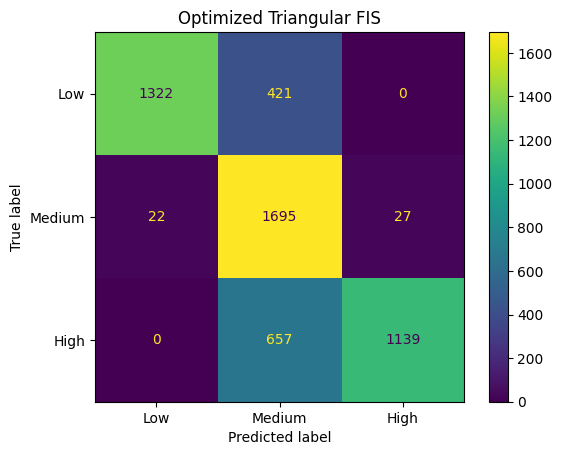

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'Low',
        'Medium',
        'High'
    ]
)

disp.plot()

plt.title(
    'Optimized Triangular FIS'
)

plt.show()

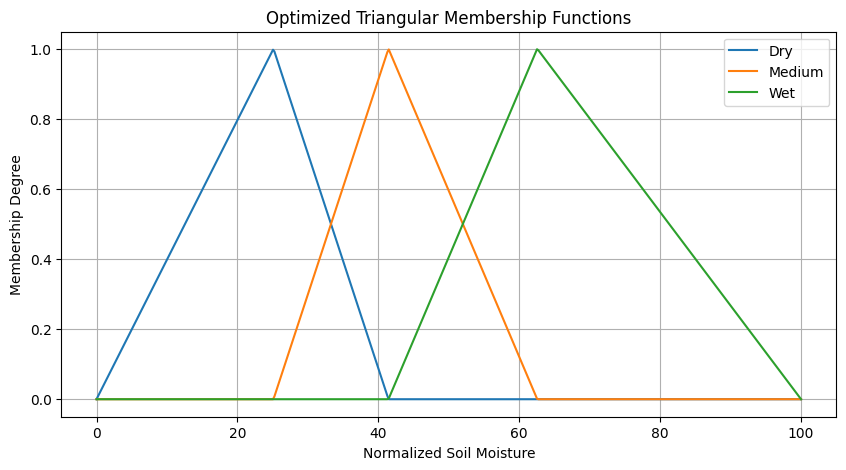

In [ ]:
x = np.linspace(
    0,
    100,
    500
)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    [
        trimf(
            v,
            0,
            best_moisture_centers[0],
            best_moisture_centers[1]
        )
        for v in x
    ],
    label='Dry'
)

plt.plot(
    x,
    [
        trimf(
            v,
            best_moisture_centers[0],
            best_moisture_centers[1],
            best_moisture_centers[2]
        )
        for v in x
    ],
    label='Medium'
)

plt.plot(
    x,
    [
        trimf(
            v,
            best_moisture_centers[1],
            best_moisture_centers[2],
            100
        )
        for v in x
    ],
    label='Wet'
)

plt.xlabel(
    'Normalized Soil Moisture'
)

plt.ylabel(
    'Membership Degree'
)

plt.title(
    'Optimized Triangular Membership Functions'
)

plt.legend()
plt.grid(True)
plt.show()